# Reconciling Two Finance Systems When the Keys Don't Line Up

After a system migration or a merger, two ledgers are supposed to hold the same transactions — but they never quite do. Some IDs get mistyped, some get lost, and some invoices get settled in several payments. A plain join on invoice number misses all of that.

This notebook builds a reconciliation engine that:
1. links records **even when the invoice ID is broken or missing** (probabilistic record linkage)
2. finds **split payments** — one invoice paid in several parts
3. classifies every record into a break type a finance team can act on
4. measures its own accuracy against known ground truth

**Data:** UCI Online Retail II — ~1M real invoice lines from a UK online retailer, 2009–2011.

## 0. Setup

In [3]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_columns", None)

## 1. Load and inspect the raw data

The file is one row per **line item**, not per invoice. Before doing anything I want to see how messy it is — missing customers and cancellations both affect how matching works later.

In [5]:
sheets = pd.read_excel("online_retail_II.xlsx", sheet_name=None)
raw = pd.concat(sheets.values(), ignore_index=True)
raw.columns = [c.strip() for c in raw.columns]
raw = raw.rename(columns={"Invoice": "InvoiceNo", "Price": "UnitPrice", "Customer ID": "CustomerID"})
print(raw.shape)
raw.head()

(1067371, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
raw.isna().mean().round(3)

InvoiceNo      0.000
StockCode      0.000
Description    0.004
Quantity       0.000
InvoiceDate    0.000
UnitPrice      0.000
CustomerID     0.228
Country        0.000
dtype: float64

In [7]:
# cancellations have invoice numbers starting with "C"
raw["InvoiceNo"].astype(str).str.startswith("C").mean()

np.float64(0.018263565339511754)

## 2. Build System A — the source ledger

Reconciliation happens at **invoice level**, so I roll the line items up to one row per invoice. Along with amount and date, I keep two fields that will matter for fuzzy matching later:
- `CustomerID` — who the invoice belongs to
- `Sig` — a short "signature" of the invoice's top 3 product codes, a cheap fingerprint of what was bought

Note on `astype(str)`: the invoice column mixes integers (`489434`) and text (`C489449`). If it isn't forced to text, joins later on silently fail to match.

In [9]:
raw["InvoiceNo"] = raw["InvoiceNo"].astype(str)
raw["Quantity"] = pd.to_numeric(raw["Quantity"], errors="coerce")
raw["UnitPrice"] = pd.to_numeric(raw["UnitPrice"], errors="coerce")
raw = raw.dropna(subset=["Quantity", "UnitPrice", "StockCode"])
raw["LineAmount"] = raw["Quantity"] * raw["UnitPrice"]

In [10]:
def top_codes(s):
    return " ".join(sorted(s.astype(str).value_counts().head(3).index))

system_a = (raw.groupby("InvoiceNo")
               .agg(Amount=("LineAmount", "sum"),
                    Date=("InvoiceDate", "min"),
                    CustomerID=("CustomerID", "first"),
                    Sig=("StockCode", top_codes))
               .reset_index())

# leave out cancellations / zero-value invoices for this version
system_a = system_a[system_a["Amount"] > 0].copy()
system_a["Amount"] = system_a["Amount"].round(2)
system_a["Date"] = pd.to_datetime(system_a["Date"]).dt.normalize()
system_a = system_a.reset_index(drop=True)

print(f"{len(system_a):,} invoices")
system_a.head()

40,078 invoices


,InvoiceNo,Amount,Date,CustomerID,Sig
0,489434,505.30,2009-12-01,13085.0,79323P 79323W 85048
1,489435,145.80,2009-12-01,13085.0,22195 22349 22350
2,489436,630.33,2009-12-01,13078.0,21754 21755 48173C
3,489437,310.75,2009-12-01,15362.0,22130 22143 22145
4,489438,2286.24,2009-12-01,18102.0,21100 21252 21329


## 3. Build System B — the target ledger, with known breaks

To measure accuracy I need to know the right answer for every record, so I build System B from a copy of A and inject breaks myself. The key point: **four of these break types are designed to defeat a normal join**, so recovering them is a real test of the engine.

| Break | What happens in B | Can a join on invoice ID catch it? |
|---|---|---|
| `AMOUNT_MISMATCH` | amount changed ±0.5–3% | yes |
| `TIMING_DIFF` | posted 1–3 days late | yes |
| `DUPLICATE` | posted twice | yes |
| `MISSING_IN_B` | never arrived in B | yes |
| `KEY_CORRUPTED` | invoice ID mistyped or re-prefixed | **no** |
| `KEY_MISSING` | invoice ID blank | **no** |
| `SPLIT` | paid as 2 parts under a payment ref, not the invoice ID | **no** |
| `MISSING_IN_A` | orphan entry in B with no source | — |

Each invoice gets at most one break, so the true label is never ambiguous.

In [12]:
ids = system_a["InvoiceNo"].sample(frac=1, random_state=SEED).tolist()
n = len(ids)

shares = {"MISSING_IN_B": 0.02, "AMOUNT_MISMATCH": 0.03, "TIMING_DIFF": 0.03,
          "KEY_CORRUPTED": 0.04, "KEY_MISSING": 0.03, "SPLIT": 0.03, "DUPLICATE": 0.01}

bucket = {}
start = 0
for brk, share in shares.items():
    k = int(n * share)
    for inv in ids[start:start + k]:
        bucket[inv] = brk
    start += k

pd.Series(bucket).value_counts()

KEY_CORRUPTED      1603
AMOUNT_MISMATCH    1202
TIMING_DIFF        1202
KEY_MISSING        1202
SPLIT              1202
MISSING_IN_B        801
DUPLICATE           400
Name: count, dtype: int64

In [13]:
def corrupt_key(k):
    # the three ways IDs usually get damaged between systems.
    # keep trying until the key actually changes: swapping two identical
    # digits (494009 -> 494009) changes nothing, which mislabelled 52 rows
    # in my first run
    for _ in range(10):
        mode = rng.integers(0, 3)
        if mode == 0 and len(k) > 1:             # dropped character
            i = rng.integers(0, len(k))
            new = k[:i] + k[i+1:]
        elif mode == 1 and len(k) > 2:           # two characters swapped
            i = rng.integers(0, len(k) - 1)
            new = k[:i] + k[i+1] + k[i] + k[i+2:]
        else:                                    # prefix added by the new system
            new = "INV-" + k
        if new != k:
            return new
    return "INV-" + k

In [14]:
b_rows = []

def post(r, amount, date, key_shown, true_break, true_inv):
    b_rows.append({"BId": f"B{len(b_rows)}", "KeyShown": key_shown,
                   "Amount": round(amount, 2), "Date": date,
                   "CustomerID": r.CustomerID, "Sig": r.Sig,
                   "TrueInv": true_inv, "TrueBreak": true_break})

for r in system_a.itertuples():
    brk = bucket.get(r.InvoiceNo, "MATCHED")

    if brk == "MISSING_IN_B":
        continue

    if brk == "SPLIT":
        part1 = round(r.Amount * rng.uniform(0.3, 0.7), 2)
        part2 = round(r.Amount - part1, 2)
        lag = pd.Timedelta(days=int(rng.integers(0, 3)))
        post(r, part1, r.Date, "", "SPLIT", r.InvoiceNo)
        post(r, part2, r.Date + lag, "", "SPLIT", r.InvoiceNo)
        continue

    amount, date, key = r.Amount, r.Date, r.InvoiceNo
    if brk == "AMOUNT_MISMATCH":
        amount = r.Amount * (1 + rng.choice([-1, 1]) * rng.uniform(0.005, 0.03))
    elif brk == "TIMING_DIFF":
        date = r.Date + pd.Timedelta(days=int(rng.integers(1, 4)))
    elif brk == "KEY_CORRUPTED":
        key = corrupt_key(r.InvoiceNo)
    elif brk == "KEY_MISSING":
        key = ""

    label = "MATCHED" if brk == "DUPLICATE" else brk
    post(r, amount, date, key, label, r.InvoiceNo)
    if brk == "DUPLICATE":
        post(r, amount, date, key, "DUPLICATE", r.InvoiceNo)

# orphans: entries in B that have no source in A
for r in system_a.sample(frac=0.01, random_state=SEED + 1).itertuples():
    post(r, r.Amount, r.Date, f"FIN{rng.integers(10000, 99999)}", "MISSING_IN_A", None)

In [15]:
b_full = pd.DataFrame(b_rows)

# the engine only ever sees system_b; the truth columns are kept aside for scoring
truth = b_full[["BId", "TrueInv", "TrueBreak"]].copy()
system_b = b_full.drop(columns=["TrueInv", "TrueBreak"])

hidden = truth["TrueBreak"].isin(["KEY_CORRUPTED", "KEY_MISSING", "SPLIT"]).sum()
print(f"System B: {len(system_b):,} rows")
print(f"Rows a join on invoice ID cannot link: {hidden:,} ({hidden/len(system_b):.1%})")
truth["TrueBreak"].value_counts()

System B: 41,280 rows
Rows a join on invoice ID cannot link: 5,209 (12.6%)


TrueBreak
MATCHED            32866
SPLIT               2404
KEY_CORRUPTED       1603
TIMING_DIFF         1202
AMOUNT_MISMATCH     1202
KEY_MISSING         1202
MISSING_IN_A         401
DUPLICATE            400
Name: count, dtype: int64

## 4. The engine

The engine runs in four stages, and **the order is deliberate**:

1. **Exact match** — take the easy, certain links first
2. **Split detection** — find groups of payments that add up to an invoice
3. **Fuzzy matching** — score the remaining records on similarity
4. **Classify** — label every record with a break type

Why splits come before fuzzy matching: in testing, running fuzzy first let it grab half-payments and pair them with the wrong invoice, which left the split finder with nothing to work with. Splits first fixed it.

### Stage 1 — exact match on invoice ID (with a sanity check)

A matching key isn't proof. Invoice numbers here are sequential, so a mistyped ID (490351 → 490531) is very often **another real invoice number**. In my first run, these **key collisions** caused 63% of all errors: the mistyped record was linked to a stranger's invoice, and the stranger's real record was then flagged as a duplicate.

So an exact match is only accepted if customer, amount (within 10%) and date (within 7 days) also roughly agree. If they don't, the record is treated as having a damaged key and goes on to fuzzy matching.

In [18]:
a = system_a.copy()
b = system_b.copy()
b["KeyShown"] = b["KeyShown"].fillna("").astype(str)

a_ids = set(a["InvoiceNo"])
a_lookup = a.set_index("InvoiceNo")
link = {}      # BId -> InvoiceNo it belongs to
method = {}    # BId -> which stage linked it
suspect = []   # key matched a real invoice, but nothing else about it did

def plausible(src, r):
    same_cust = pd.isna(src.CustomerID) or pd.isna(r.CustomerID) or src.CustomerID == r.CustomerID
    close_amt = abs(src.Amount - r.Amount) <= 0.10 * src.Amount
    close_date = abs((src.Date - r.Date).days) <= 7
    return same_cust and close_amt and close_date

for r in b.itertuples():
    if r.KeyShown in a_ids:
        if plausible(a_lookup.loc[r.KeyShown], r):
            link[r.BId] = r.KeyShown
            method[r.BId] = "exact"
        else:
            suspect.append(r.BId)   # left loose, so split/fuzzy matching gets a go

print(f"Exact matches:              {len(link):,} of {len(b):,} rows")
print(f"Rejected as key collisions: {len(suspect):,}")
print(f"Left over:                  {len(b) - len(link):,}")

Exact matches:              35,670 of 41,280 rows
Rejected as key collisions: 178
Left over:                  5,610


### Blocking — so we don't compare everything with everything

Comparing every leftover B row with every A invoice grows as n². On the full dataset that's billions of comparisons. **Blocking** only compares records that share a cheap key — here the customer, or the month when the customer is missing. A real match almost always shares its customer, so very little is lost.

In [20]:
def block_key(cust, date):
    if pd.notna(cust):
        return f"C{int(cust)}"
    return f"M{date:%Y-%m}"

a["blk"] = [block_key(c, d) for c, d in zip(a["CustomerID"], a["Date"])]
b["blk"] = [block_key(c, d) for c, d in zip(b["CustomerID"], b["Date"])]
a["blk"].value_counts().describe()

count    5903.000000
mean        6.789429
std        15.214780
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       398.000000
Name: count, dtype: float64

### Stage 2 — split detection

For each invoice still unlinked, look in its block for **2 or 3 loose payments that add up to it** (within 2 cents) and were posted within 5 days of each other.

Two things keep this from being slow or wrong:
- **pairs use a "two-sum" lookup**: for each payment, check whether the missing amount has already been seen — one pass instead of trying every pair
- **every part must be smaller than the invoice**, so a full-size record can't be used as a "part"

In [22]:
SUM_TOL = 0.02
PART_WINDOW = 5   # days

def find_pair(parts, target):
    seen = {}
    for p in parts:
        need = target - p.Amount
        for cents in (-2, -1, 0, 1, 2):
            q = seen.get(round(need + cents / 100, 2))
            if q is not None and abs((p.Date - q.Date).days) <= PART_WINDOW:
                return (q, p)
        seen[round(p.Amount, 2)] = p
    return None

def find_triple(parts, target):
    if len(parts) > 40:       # cap the search on very big blocks
        return None
    for combo in itertools.combinations(parts, 3):
        if abs(sum(p.Amount for p in combo) - target) <= SUM_TOL:
            if (max(p.Date for p in combo) - min(p.Date for p in combo)).days <= PART_WINDOW:
                return combo
    return None

In [23]:
used_a = set(link.values())
loose_b = {k: g for k, g in b[~b["BId"].isin(link)].groupby("blk")}
split_groups = []

for r in a[~a["InvoiceNo"].isin(used_a)].itertuples():
    pool = loose_b.get(r.blk)
    if pool is None:
        continue
    parts = [p for p in pool.itertuples()
             if p.BId not in link and p.Amount < r.Amount - SUM_TOL]
    found = find_pair(parts, r.Amount) or find_triple(parts, r.Amount)
    if found:
        for p in found:
            link[p.BId] = r.InvoiceNo
            method[p.BId] = "split"
        used_a.add(r.InvoiceNo)
        split_groups.append((r.InvoiceNo, [p.BId for p in found]))

print(f"Split settlements found: {len(split_groups):,}")
split_groups[:5]

Split settlements found: 1,197


[('489669', ['B122', 'B123']),
 ('489670', ['B124', 'B125']),
 ('489672', ['B127', 'B128']),
 ('489684', ['B140', 'B141']),
 ('489702', ['B146', 'B147'])]

### Stage 3 — fuzzy matching (probabilistic record linkage)

What's left is mostly records whose ID was damaged or lost. For each candidate pair in the same block, I score four fields from 0 to 1 and blend them:

| Field | Score | Weight |
|---|---|---|
| Amount | 1 − relative difference | 0.45 |
| Date | 1 − days apart / 7 | 0.25 |
| Customer | 1 if same, else 0 — **left out if missing** | 0.15 |
| Signature | overlap of product codes (Jaccard) | 0.15 |

This is a simplified version of the **Fellegi–Sunter** model — each field adds evidence for or against a match. I kept the scoring transparent on purpose: in an audit, you have to be able to explain *why* two records were linked.

**Missing customer = no information, not a disagreement.** In my first version a missing customer scored 0, so those records could never score above 0.85 — and the threshold quietly filtered them out. Now the customer weight is dropped when it's missing and the other weights are rescaled.

In [25]:
WEIGHTS = {"amount": 0.45, "date": 0.25, "customer": 0.15, "sig": 0.15}
DATE_WINDOW = 7

def amount_sim(x, y):
    return max(0.0, 1 - abs(x - y) / max(abs(x), abs(y), 1e-9))

def date_sim(x, y):
    return max(0.0, 1 - abs((x - y).days) / DATE_WINDOW)

def customer_sim(x, y):
    return 1.0 if x == y else 0.0

def sig_sim(x, y):
    sx, sy = set(str(x).split()), set(str(y).split())
    return len(sx & sy) / len(sx | sy) if sx and sy else 0.0

def pair_score(ra, rb):
    sims = {"amount": amount_sim(ra.Amount, rb.Amount),
            "date":   date_sim(ra.Date, rb.Date),
            "sig":    sig_sim(ra.Sig, rb.Sig)}
    w = dict(WEIGHTS)
    if pd.isna(ra.CustomerID) or pd.isna(rb.CustomerID):
        w.pop("customer")           # missing: no evidence either way
    else:
        sims["customer"] = customer_sim(ra.CustomerID, rb.CustomerID)
    return sum(w[k] * sims[k] for k in w) / sum(w.values())

In [26]:
open_a = a[~a["InvoiceNo"].isin(used_a)]
open_b = b[~b["BId"].isin(link)]
a_pool = {k: g for k, g in open_a.groupby("blk")}

candidates = []   # (score, BId, InvoiceNo)
comparisons = 0
for rb in open_b.itertuples():
    pool = a_pool.get(rb.blk)
    if pool is None:
        continue
    for ra in pool.itertuples():
        comparisons += 1
        s = pair_score(ra, rb)
        if s >= 0.5:                      # don't bother storing hopeless pairs
            candidates.append((s, rb.BId, ra.InvoiceNo))

naive = len(open_a) * len(open_b)
print(f"Comparisons with blocking:    {comparisons:,}")
print(f"Comparisons without blocking: {naive:,}")
print(f"Candidate pairs kept:         {len(candidates):,}")

Comparisons with blocking:    13,221
Comparisons without blocking: 11,605,754
Candidate pairs kept:         4,753


Assignment is greedy: take the highest-scoring pair, lock both records, repeat. A pair is only accepted above a **threshold** — section 7 shows how that number was chosen instead of guessed.

In [28]:
THRESHOLD = 0.80

def assign(candidates, threshold, already_used):
    taken = set(already_used)
    chosen = {}
    for s, bid, inv in sorted(candidates, reverse=True):
        if s < threshold:
            break
        if bid in chosen or inv in taken:
            continue
        chosen[bid] = inv
        taken.add(inv)
    return chosen

fuzzy = assign(candidates, THRESHOLD, used_a)
for bid, inv in fuzzy.items():
    link[bid] = inv
    method[bid] = "fuzzy"
used_a |= set(fuzzy.values())

pd.Series(method).value_counts()

exact    35670
fuzzy     2803
split     2396
Name: count, dtype: int64

### Stage 4 — classify every record

Linking says *which* records belong together. The client needs to know *what's wrong* with each one, so every B row gets a break type, and every A invoice that never got linked is flagged as missing from B.

In [30]:
AMOUNT_TOL = 0.01   # materiality: ignore differences under 1 cent

a_idx = a.set_index("InvoiceNo")
b["LinkedInv"] = b["BId"].map(link)
b["Method"] = b["BId"].map(method).fillna("none")

def classify(r):
    if r.Method == "none":
        return "MISSING_IN_A"
    if r.Method == "split":
        return "SPLIT"
    if r.Method == "fuzzy":
        return "KEY_MISSING" if r.KeyShown == "" else "KEY_CORRUPTED"
    src = a_idx.loc[r.LinkedInv]
    if abs(src.Amount - r.Amount) > AMOUNT_TOL:
        return "AMOUNT_MISMATCH"
    if src.Date != r.Date:
        return "TIMING_DIFF"
    return "MATCHED"

b["Predicted"] = b.apply(classify, axis=1)

# a second posting against the same invoice is a duplicate
one_to_one = b[b["Method"] == "exact"]
dups = one_to_one[one_to_one.duplicated("LinkedInv", keep="first")].index
b.loc[dups, "Predicted"] = "DUPLICATE"

missing_in_b = a[~a["InvoiceNo"].isin(used_a)]
print(f"Invoices in A never found in B: {len(missing_in_b):,}")

Invoices in A never found in B: 808


## 5. The reconciliation report

This is what a finance team or client would actually read: how many records fall into each break type and how much money is involved.

In [32]:
report = (b.groupby("Predicted")
           .agg(records=("BId", "count"), value=("Amount", "sum")))
report.loc["MISSING_IN_B"] = [len(missing_in_b), missing_in_b["Amount"].sum()]
report = report.sort_values("value", ascending=False)
report["records"] = report["records"].astype(int)
report["value"] = report["value"].round(2)
report

,records,value
Predicted,,
MATCHED,32866,17319312.22
KEY_CORRUPTED,1613,872034.76
TIMING_DIFF,1202,607144.41
SPLIT,2396,594986.46
AMOUNT_MISMATCH,1202,582185.48
KEY_MISSING,1190,565448.73
MISSING_IN_B,808,432267.33
MISSING_IN_A,411,214674.94
DUPLICATE,400,212142.80


In [33]:
recovered = b[b["Method"].isin(["fuzzy", "split"])]
print(f"Records a plain join would have dropped but the engine linked: {len(recovered):,}")
print(f"Value of those records: {recovered['Amount'].sum():,.2f}")

b.drop(columns=["blk"]).to_csv("reconciliation_report.csv", index=False)

Records a plain join would have dropped but the engine linked: 5,199
Value of those records: 2,032,469.95


## 6. How accurate is it?

Because I built System B, I know the true answer for every row. Two questions:
- **Linking:** was each B row attached to the correct invoice?
- **Classifying:** was it given the correct break type?

Per-class precision and recall matter more than one overall number — a model can score 95% overall while missing every split.

In [35]:
check = b.merge(truth, on="BId")

should_link = check[check["TrueInv"].notna()]
link_acc = (should_link["LinkedInv"] == should_link["TrueInv"]).mean()
print(f"Linking accuracy: {link_acc:.1%}")

true_missing_b = set(a["InvoiceNo"]) - set(truth["TrueInv"].dropna())
found_missing_b = set(missing_in_b["InvoiceNo"])
hit = len(true_missing_b & found_missing_b)
print(f"MISSING_IN_B   precision {hit/max(len(found_missing_b),1):.2f}   recall {hit/max(len(true_missing_b),1):.2f}")

Linking accuracy: 99.9%
MISSING_IN_B   precision 0.99   recall 0.99


In [36]:
labels = ["MATCHED", "AMOUNT_MISMATCH", "TIMING_DIFF", "DUPLICATE",
          "KEY_CORRUPTED", "KEY_MISSING", "SPLIT", "MISSING_IN_A"]
print(classification_report(check["TrueBreak"], check["Predicted"], labels=labels, zero_division=0))

                 precision    recall  f1-score   support

        MATCHED       1.00      1.00      1.00     32866
AMOUNT_MISMATCH       1.00      1.00      1.00      1202
    TIMING_DIFF       1.00      1.00      1.00      1202
      DUPLICATE       1.00      1.00      1.00       400
  KEY_CORRUPTED       0.98      0.99      0.99      1603
    KEY_MISSING       1.00      0.99      0.99      1202
          SPLIT       1.00      1.00      1.00      2404
   MISSING_IN_A       0.91      0.93      0.92       401

       accuracy                           1.00     41280
      macro avg       0.99      0.99      0.99     41280
   weighted avg       1.00      1.00      1.00     41280



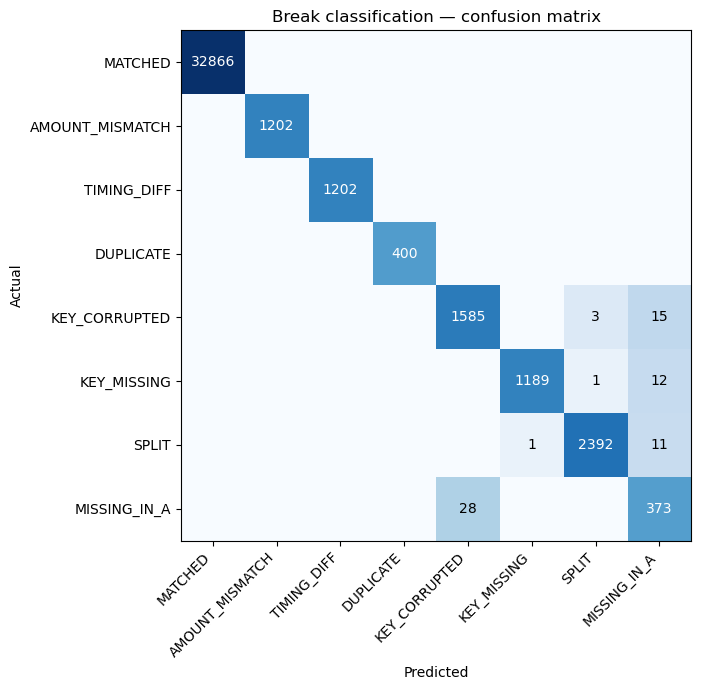

In [37]:
cm = confusion_matrix(check["TrueBreak"], check["Predicted"], labels=labels)

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(np.log1p(cm), cmap="Blues")   # log scale so the small classes are visible
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if np.log1p(cm[i, j]) > np.log1p(cm).max() / 2 else "black")
ax.set_title("Break classification — confusion matrix")
plt.tight_layout()
plt.show()

### Where it goes wrong

The errors are more useful than the score. Each one below is a case worth explaining in an interview.

In [39]:
errors = check[check["Predicted"] != check["TrueBreak"]]
print(f"{len(errors)} misclassified rows")
errors[["BId", "KeyShown", "Amount", "Method", "LinkedInv", "TrueInv", "Predicted", "TrueBreak"]].head(15)

71 misclassified rows


,BId,KeyShown,Amount,Method,LinkedInv,TrueInv,Predicted,TrueBreak
2075,B2075,,182.46,none,NaN,494441,MISSING_IN_A,KEY_MISSING
7260,B7260,,421.90,none,NaN,506582,MISSING_IN_A,SPLIT
7261,B7261,,337.46,none,NaN,506582,MISSING_IN_A,SPLIT
11189,B11189,517581,227.65,none,NaN,515781,MISSING_IN_A,KEY_CORRUPTED
13895,B13895,251795,1426.24,none,NaN,521795,MISSING_IN_A,KEY_CORRUPTED
14757,B14757,,339.48,none,NaN,523586,MISSING_IN_A,KEY_MISSING
15714,B15714,52541,598.50,none,NaN,525441,MISSING_IN_A,KEY_CORRUPTED
16763,B16763,INV-527712,21.00,none,NaN,527712,MISSING_IN_A,KEY_CORRUPTED
18184,B18184,,473.33,none,NaN,531232,MISSING_IN_A,KEY_MISSING
18565,B18565,,481.84,none,NaN,532052,MISSING_IN_A,KEY_MISSING


In [40]:
pd.crosstab(errors["TrueBreak"], errors["Predicted"])

Predicted,KEY_CORRUPTED,KEY_MISSING,MISSING_IN_A,SPLIT
TrueBreak,,,,
KEY_CORRUPTED,0,0,15,3
KEY_MISSING,0,0,12,1
MISSING_IN_A,28,0,0,0
SPLIT,0,1,11,0


## 7. Choosing the threshold

The fuzzy threshold is a trade-off, not a constant:
- **lower** it → more broken-key records recovered (recall up), but more wrong links (precision down)
- **raise** it → fewer wrong links, but more records left for manual review

The candidate scores are already computed, so I can re-run just the assignment step at different thresholds and see the trade-off directly.

In [42]:
true_inv = truth.set_index("BId")["TrueInv"].to_dict()
key_broken = set(truth.loc[truth["TrueBreak"].isin(["KEY_CORRUPTED", "KEY_MISSING"]), "BId"])
used_before_fuzzy = used_a - set(fuzzy.values())

sweep = []
for t in np.arange(0.55, 1.00, 0.05):
    picked = assign(candidates, t, used_before_fuzzy)
    correct = sum(true_inv.get(bid) == inv for bid, inv in picked.items())
    precision = correct / len(picked) if picked else 1.0
    recall = sum(true_inv.get(bid) == picked.get(bid) for bid in key_broken) / len(key_broken)
    sweep.append((round(t, 2), len(picked), precision, recall))

sweep = pd.DataFrame(sweep, columns=["threshold", "fuzzy_links", "precision", "recall"])
sweep

,threshold,fuzzy_links,precision,recall
0,0.55,2835,0.980600,0.988592
1,0.60,2814,0.987918,0.988592
2,0.65,2812,0.988620,0.988592
3,0.70,2808,0.989316,0.988592
4,0.75,2806,0.989309,0.988592
5,0.80,2803,0.989654,0.988592
6,0.85,2802,0.989650,0.988592
7,0.90,2802,0.989650,0.988592
8,0.95,2802,0.989650,0.988592


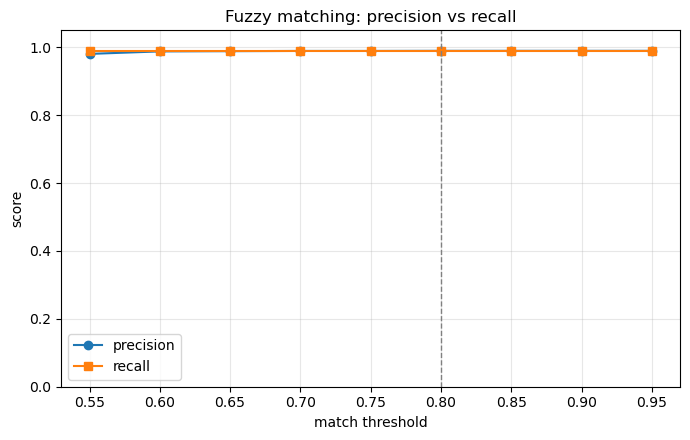

In [43]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sweep["threshold"], sweep["precision"], marker="o", label="precision")
ax.plot(sweep["threshold"], sweep["recall"], marker="s", label="recall")
ax.axvline(THRESHOLD, ls="--", color="grey", lw=1)
ax.set_xlabel("match threshold")
ax.set_ylabel("score")
ax.set_ylim(0, 1.05)
ax.set_title("Fuzzy matching: precision vs recall")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
taken = set(check.loc[(check.TrueBreak == "MISSING_IN_A") & (check.Predicted == "KEY_CORRUPTED"), "LinkedInv"])
stranded = check[check.TrueBreak.isin(["KEY_CORRUPTED", "KEY_MISSING"]) & (check.Predicted == "MISSING_IN_A")]
stranded["TrueInv"].isin(taken).mean()

np.float64(0.8888888888888888)

In [45]:
split_taken = set(check.loc[(check.Method == "split") & (check.TrueBreak != "SPLIT"), "LinkedInv"])
stranded.loc[~stranded["TrueInv"].isin(taken), "TrueInv"].isin(split_taken)

18184     True
27172    False
29144     True
Name: TrueInv, dtype: bool

## 8. Findings and limitations

### First run → diagnosis → fix

The first version scored **99% overall** on 41,280 records but still made **348 mistakes**. Grouping the errors by cause showed four sources:

| Cause | Errors | Share | What happened |
|---|---|---|---|
| Key collisions | 219 | 63% | a mistyped ID matched another real invoice; the record was linked to the wrong invoice, and that invoice's real record was then flagged `DUPLICATE` |
| Bug in my test data | 52 | 15% | swapping two identical digits left the "corrupted" key unchanged — the engine was right, the label was wrong |
| Identical orphan entries | 63 | 18% | an orphan row identical to a real invoice takes its match |
| Splits not found | 14 | 4% | parts of 7 split invoices not reassembled |

Fixes: check exact matches against customer, amount and date (section 4); make the test corruption always change the key (section 3); treat a missing customer as neutral in scoring.

The threshold sweep showed a second problem: recall dropped from **0.91 to 0.84 above 0.80**, because records with no customer ID could never score above 0.85. Treating missing values as neutral removed that ceiling.

### Results after the fixes

| | First run | Final |
|---|---|---|
| Misclassified rows | 348 | **71** (−80%) |
| Linking accuracy | — | **99.9%** |
| `KEY_CORRUPTED` recall | 0.86 | **0.99** |
| `DUPLICATE` precision | 0.75 | **1.00** |
| `AMOUNT_MISMATCH` precision | 0.93 | **1.00** |

### What it does well
- 5,209 records in System B (12.6%) can't be linked by a join on invoice number. The engine correctly links **5,166** of them (≈ £2.0M):
  - 1,585 of 1,603 mistyped IDs
  - 1,189 of 1,202 blank IDs
  - 1,196 of 1,202 split invoices (2,392 of 2,404 payment rows)
- Finds invoices that never reached System B with precision and recall of 0.99.

### Where it still struggles
70 of the 71 remaining errors are explained:

| Cause | Errors |
|---|---|
| Orphan entries identical to a real invoice (28 wrong links + 24 records pushed out) | 52 |
| Split payments not reassembled | 12 |
| Coincidental splits — two unrelated amounts that happened to add up (4 wrong links + 2 records pushed out) | 6 |
| Unexplained | 1 |

- **Errors come in pairs:** a wrong link takes an invoice, so the record that really belonged to it is left unmatched. Ties and borderline scores should go to manual review, not be guessed.
- **Identical entries can't be told apart:** no similarity score can pick the genuine one of two identical candidates.
- When a customer ID is missing, blocking falls back to the whole month: a bigger pool, so more chances of a wrong link.
- Field weights are set by hand. With labelled matches they could be **learned** (e.g. logistic regression on the four field scores).

### Honest caveat
The discrepancies are simulated. Mistyped and blank-ID records keep their exact amount, date and customer, which is why the threshold sweep is almost flat: true matches score close to 1.0. Real data is messier, so these results are an upper bound, not a production guarantee.

### Next steps
- add noise to the simulated breaks (small amount and date shifts) so the threshold has a real trade-off
- a manual-review queue for ties and near-threshold scores
- learn the weights instead of setting them by hand
- handle cancellations and credit notes as their own break type